# Bölüm 13 – Makale Yeniden Üretimi: REPID ile Bölgesel Etki Grafikleri

**Öğrenci:** Serap Şahin (20269348009)

**Makale:** Herbinger, J., Bischl, B. ve Casalicchio, G. (2022). *REPID: Regional Effect Plots with implicit Interaction
Detection.* Proceedings of the 25th International Conference on Artificial Intelligence and Statistics (AISTATS),
PMLR 151, 10209–10233. arXiv:2202.07254 · Yazarların kodu (R): github.com/JuliaHerbinger/repid

**İzlencedeki tip:** Seçenek 2 (Kıyaslama). ICE eğrilerini gruplamada REPID ile k-ortalamaların, grup içi benzerlik ve
yorumlanabilirlik açısından karşılaştırılması.

**Ana soru:** PDP, ICE eğrilerinin ortalamasıdır. Bir öznitelik başka özniteliklerle etkileşim içindeyse ICE eğrileri
farklı şekillerde gider ve ortalama bu farkı gizler. REPID, ICE eğrilerini **bir karar ağacıyla** benzer şekilli
eğrilerin bir arada olduğu bölgelere ayırır. Her bölgenin kendi PDP'si olur ve bölünmenin hangi öznitelikte yapıldığı,
etkileşimin hangi öznitelikle olduğunu gösterir.

**Bölüm 13 uygulamamla bağı:** Uygulamamda c-ICE eğrilerini k-ortalamalarla kümelemiştim. Kümeler veriden çıkıyordu ama
bir kurala karşılık gelmiyordu; hangi bölgelerden oluştuklarına sonradan bakmıştım. REPID aynı işi **yorumlanabilir
kurallarla** yapıyor (ör. "enlem ≤ 34,5").

**Defterin akışı**

| Kısım | İçerik | Derste |
|---|---|---|
| 1 | Yöntemi sıfırdan yazmak: merkezleme, heterojenlik, en iyi bölünme, ağaç | 🔴 **Canlı** |
| 2 | Makalenin simülasyonu (Bölüm 3): bilinen etkileşimleri buluyor mu? | 🔴 **Canlı** + hazır |
| 3 | Makalenin gerçek veri örneği: California Housing, boylam için bölgesel PDP (Şekil 6) | Hazır |
| 4 | Kendi verim: Bölüm 13 uygulamamdaki model ve gelir ICE'leri; REPID ve k-ortalamalar | Hazır |
| 5 | Sınırlamalar | Tartışma |

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#EBEBEB",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
BOLGE_RENK = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02", "#a6761d", "#666666"]

# veri.csv = California Housing (Bölüm 13 uygulamamdaki ve makalenin deposundaki dosyayla aynı).
# Dosya bulunamazsa aynı sabit sürüm GitHub'dan indirilir.
VERI = ("veri.csv", "https://raw.githubusercontent.com/ageron/handson-ml2/"
                    "7b7e23e7267356f8355580877eff98c43cda1bd0/datasets/housing/housing.csv")


SEKIL = Path("sekiller")
SEKIL.mkdir(exist_ok=True)


def goster(fig, ad):
    """Grafiği sunumda kullanmak için sekiller/ klasörüne kaydeder ve gösterir."""
    fig.savefig(SEKIL / ad, dpi=150, bbox_inches="tight")
    plt.show()


def veri_oku():
    return pd.read_csv(VERI[0] if Path(VERI[0]).exists() else VERI[1])


def ice_hesapla(tahmin_fn, X, ozellik, izgara):
    """n x K ICE matrisi (satır = gözlem, sütun = ızgara noktası). Bölüm 13 uygulamamdaki fonksiyon."""
    n, K = len(X), len(izgara)
    X_cogul = pd.concat([X] * K, ignore_index=True)
    X_cogul[ozellik] = np.repeat(np.asarray(izgara), n)
    return np.asarray(tahmin_fn(X_cogul)).reshape(K, n).T

## 1. 🔴 Canlı kodlama: REPID'i sıfırdan yazmak

Yazarların koduna (`R/tree_splitting.R`, `R/helper_general.R`) göre algoritma dört parçadan oluşuyor.

**1. Merkezleme.** Her ICE eğrisi **kendi ortalamasına** göre merkezlenir: $\tilde{f}^{(i)}(z_k) = \hat f^{(i)}(z_k) -
\frac{1}{K}\sum_{k'} \hat f^{(i)}(z_{k'})$. Böylece eğriler arasındaki **seviye** farkı silinir, sadece **şekil** farkı kalır.
(Bölüm 13 uygulamamdaki c-ICE eğriyi sol uçta sıfırlıyordu; REPID ortalamada sıfırlıyor. İkisi de seviyeyi siler.)

**2. Heterojenlik.** Bir bölgedeki eğrilerin, o bölgenin ortalama eğrisinden (bölgesel PDP) kare uzaklıklarının toplamı:

$$\mathcal{R}(\mathcal{N}) = \sum_{i \in \mathcal{N}} \sum_{k=1}^{K} \big(\tilde f^{(i)}(z_k) - \bar{\tilde f}_{\mathcal{N}}(z_k)\big)^2$$

Bölgedeki bütün eğriler aynı şekildeyse $\mathcal{R} = 0$; PDP bu bölgeyi tam temsil eder.

**3. En iyi bölünme.** İlgilenilen öznitelik dışındaki her öznitelik ve her eşik için düğüm ikiye bölünür; iki çocuğun
heterojenlik toplamı en küçük olan seçilir. Her çocukta en az `min_dugum` gözlem olmalı.

**4. Durma kuralı.** Bir bölünmenin kazancı **kökteki toplam heterojenliğe göre** ölçülür:
$\text{kazanç} = (\mathcal{R}_{\text{düğüm}} - \mathcal{R}_{\text{sol}} - \mathcal{R}_{\text{sağ}}) / \mathcal{R}_{\text{kök}}$.
İlk bölünme kazanç $\geq$ `esik` ise yapılır; sonraki bölünmeler, bir önceki bölünmenin kazancının `esik` katından
büyükse yapılır. En fazla `derinlik` kadar bölünür.

**Etkileşim ölçüsü.** Bir özniteliğe yapılan bölünmelerin kazançlarının toplamı, ICE heterojenliğinin ne kadarının o
öznitelikle açıklandığını gösterir. Hiç bölünme yapılmayan öznitelik, bu verilere göre ilgilenilen öznitelikle
etkileşim içinde değildir.

In [2]:
def merkezle(ice):
    """REPID merkezlemesi: her eğri kendi ortalamasına göre."""
    return ice - ice.mean(axis=1, keepdims=True)


def heterojenlik(Y):
    """Eğrilerin ortalama eğriden kare uzaklıklarının toplamı."""
    return float(((Y - Y.mean(axis=0)) ** 2).sum())


def en_iyi_bolunme_yavas(Y, X, min_dugum=10):
    """Tanımın kendisi: her öznitelik ve her eşik için iki çocuğun heterojenliğini topla, en küçüğünü seç."""
    en_iyi = (np.inf, None, None)
    for oz in X.columns:
        x = X[oz].to_numpy(dtype=float)
        degerler = np.unique(x)
        for t in (degerler[:-1] + degerler[1:]) / 2:          # ardışık iki değerin ortası
            sol = x <= t
            if sol.sum() < min_dugum or (~sol).sum() < min_dugum:
                continue
            toplam = heterojenlik(Y[sol]) + heterojenlik(Y[~sol])
            if toplam < en_iyi[0]:
                en_iyi = (toplam, oz, t)
    return en_iyi


def en_iyi_bolunme(Y, X, min_dugum=10):
    """Aynı sonucu kümülatif toplamlarla hızlı bulur (büyük veri için).
    Heterojenlik = Σ‖y‖² − n·‖ȳ‖²; sıralı veride bu iki terim kümülatif toplamla her eşik için tek adımda bulunur."""
    n = len(Y)
    kare = (Y ** 2).sum(axis=1)
    en_iyi = (np.inf, None, None)
    for oz in X.columns:
        x = X[oz].to_numpy(dtype=float)
        sira = np.argsort(x, kind="stable")
        xs = x[sira]
        S, Q = np.cumsum(Y[sira], axis=0), np.cumsum(kare[sira])
        i = np.arange(min_dugum - 1, n - min_dugum)              # sol çocuk = sıralı ilk i+1 gözlem
        i = i[xs[i] < xs[i + 1]]                                  # yalnızca değerin değiştiği yerlerde bölünebilir
        if len(i) == 0:
            continue
        n_sol, n_sag = i + 1, n - i - 1
        S_sag = S[-1] - S[i]
        toplam = (Q[i] - (S[i] ** 2).sum(1) / n_sol) + ((Q[-1] - Q[i]) - (S_sag ** 2).sum(1) / n_sag)
        k = int(np.argmin(toplam))
        if toplam[k] < en_iyi[0]:
            en_iyi = (float(toplam[k]), oz, float((xs[i[k]] + xs[i[k] + 1]) / 2))
    return en_iyi


def repid(Y, X, derinlik=3, esik=0.1, min_dugum=10, bolucu=en_iyi_bolunme):
    """REPID ağacı. Y: merkezlenmiş ICE (n x K), X: bölmede kullanılacak öznitelikler.
    Döndürür: yaprak listesi (her biri: gözlem indeksleri ve kuralı), bölünme tablosu, kök heterojenliği."""
    kok = heterojenlik(Y)
    kuyruk = [{"idx": np.arange(len(Y)), "derinlik": 0, "onceki": 0.0, "kural": []}]
    yapraklar, bolunmeler = [], []
    while kuyruk:
        d = kuyruk.pop(0)
        Yd, Xd = Y[d["idx"]], X.iloc[d["idx"]]
        if d["derinlik"] >= derinlik or len(d["idx"]) < min_dugum:
            yapraklar.append(d)
            continue
        toplam, oz, t = bolucu(Yd, Xd, min_dugum)
        kazanc = (heterojenlik(Yd) - toplam) / kok if oz is not None else 0.0
        sinir = esik if d["onceki"] == 0 else d["onceki"] * esik
        if oz is None or kazanc < sinir:
            yapraklar.append(d)
            continue
        bolunmeler.append({"derinlik": d["derinlik"] + 1, "bölünen düğüm": " & ".join(d["kural"]) or "tüm veri",
                           "öznitelik": oz, "eşik": round(t, 3), "kazanç": kazanc, "n": len(d["idx"])})
        sol = Xd[oz].to_numpy() <= t
        for maske, isaret in [(sol, "≤"), (~sol, ">")]:
            kuyruk.append({"idx": d["idx"][maske], "derinlik": d["derinlik"] + 1, "onceki": kazanc,
                           "kural": d["kural"] + [f"{oz} {isaret} {t:.2f}"]})
    return yapraklar, pd.DataFrame(bolunmeler), kok


def etkilesim_olcusu(bolunmeler, oznitelikler):
    """Her özniteliğe yapılan bölünmelerin kazanç toplamı (ICE heterojenliğinin açıklanan payı)."""
    olcu = pd.Series(0.0, index=oznitelikler)
    if len(bolunmeler):
        olcu = olcu.add(bolunmeler.groupby("öznitelik")["kazanç"].sum(), fill_value=0)
    return olcu.sort_values(ascending=False)


def bolgesel_ciz(eksenler, izgara, ice, yapraklar, renkler=BOLGE_RENK, alfa=0.15, gercek=None):
    """Her yaprak için ICE eğrileri ve bölgesel PDP (kalın)."""
    for ax, d, r in zip(eksenler, yapraklar, renkler):
        ax.plot(izgara, ice[d["idx"]].T, color=r, alpha=alfa, lw=0.7)
        ax.plot(izgara, ice[d["idx"]].mean(0), color="k", lw=2.5, label="bölgesel PDP")
        if gercek is not None:
            ax.plot(izgara, gercek(d), color="#d62728", lw=1.5, ls="--", label="gerçek eğim")
        ax.set_title(" & ".join(d["kural"]) or "tüm veri", fontsize=9)
        ax.text(0.02, 0.95, f"n = {len(d['idx'])}", transform=ax.transAxes, va="top", fontsize=8)

## 2. Makalenin simülasyonu (makale Bölüm 3; `analysis_sim_vine_vs_repid.R`)

Yazarların kurgusu: $n = 500$, $x_1, x_2 \sim U(-1, 1)$, $x_3 \sim \text{Bernoulli}(0{,}5)$,
$x_4 \sim \text{Bernoulli}(0{,}3)$, gürültü öznitelikleri $x_5 \sim \text{Bernoulli}(0{,}5)$, $x_6 \sim N(1, 5^2)$ ve

$$y = 0{,}2\,x_1 - 8\,x_2 + 16\,x_2\,\mathbb{1}(x_3 = 0) + 8\,x_2\,\mathbb{1}(x_1 > \bar{x}_1) + \varepsilon,\qquad \varepsilon \sim N(0,1)$$

$x_2$'nin etkisi $x_3$ ve $x_1$'e bağlı. Gerçek eğimler dört bölgede: $x_3 = 1, x_1 \le 0$: **−8**;
$x_3 = 1, x_1 > 0$: **0**; $x_3 = 0, x_1 \le 0$: **+8**; $x_3 = 0, x_1 > 0$: **+16**. PDP'nin eğimi bunların
ortalaması (yaklaşık +4) ve hiçbir bölgeyi temsil etmiyor.

Model: rastgele orman (yazarlarda `ranger`, 500 ağaç; burada scikit-learn'ün karşılığı). $x_2$ için 20 noktalı ızgara.
Beklenen: REPID önce $x_3$'e, sonra iki tarafta da $x_1 \approx 0$'a bölmeli; $x_4, x_5, x_6$'ya hiç bölmemeli.

**Ayar:** Yazarlar bu örnekte ağacı durma kuralıyla değil, iki seviyeyi **elle** bölerek kuruyor (her çocukta en iyi
bölünme). Bunun karşılığı `derinlik = 2`, `esik = 0`.

In [3]:
rng = np.random.default_rng(1234)
n = 500
sim = pd.DataFrame({"x1": rng.uniform(-1, 1, n), "x2": rng.uniform(-1, 1, n),
                    "x3": rng.choice([0, 1], n, p=[0.5, 0.5]), "x4": rng.choice([0, 1], n, p=[0.7, 0.3]),
                    "x5": rng.choice([0, 1], n, p=[0.5, 0.5]), "x6": rng.normal(1, 5, n)})
sim["y"] = (0.2 * sim.x1 - 8 * sim.x2 + np.where(sim.x3 == 0, 16 * sim.x2, 0)
            + np.where(sim.x1 > sim.x1.mean(), 8 * sim.x2, 0) + rng.normal(0, 1, n))
SIM_OZ = ["x1", "x2", "x3", "x4", "x5", "x6"]
rf_sim = RandomForestRegressor(n_estimators=500, max_features=2, min_samples_leaf=5, random_state=1234, n_jobs=-1)
rf_sim.fit(sim[SIM_OZ], sim["y"])
iz_sim = np.linspace(sim.x2.min(), sim.x2.max(), 20)
ice_sim = ice_hesapla(lambda D: rf_sim.predict(D[SIM_OZ]), sim[SIM_OZ], "x2", iz_sim)
Y_sim = merkezle(ice_sim)
X_sim = sim[["x1", "x3", "x4", "x5", "x6"]]           # bölünme adayları: x2 dışındaki öznitelikler
print(f"ICE matrisi: {Y_sim.shape}, kökteki heterojenlik: {heterojenlik(Y_sim):.0f}")

ICE matrisi: (500, 20), kökteki heterojenlik: 88918


In [4]:
# 🔴 Canlı: ilk bölünmeyi tanımın kendisiyle (yavaş sürüm) bul
t0 = time.time()
yavas = en_iyi_bolunme_yavas(Y_sim, X_sim)
t1 = time.time()
hizli = en_iyi_bolunme(Y_sim, X_sim)
t2 = time.time()
print(f"Yavaş sürüm: {yavas[1]} ≤ {yavas[2]:.3f}, heterojenlik {yavas[0]:.1f}  ({t1 - t0:.2f} sn)")
print(f"Hızlı sürüm: {hizli[1]} ≤ {hizli[2]:.3f}, heterojenlik {hizli[0]:.1f}  ({t2 - t1:.3f} sn)")
assert yavas[1] == hizli[1] and np.isclose(yavas[0], hizli[0]) and np.isclose(yavas[2], hizli[2])
print("✔ İki sürüm aynı bölünmeyi buluyor.")

Yavaş sürüm: x3 ≤ 0.500, heterojenlik 15614.2  (0.04 sn)
Hızlı sürüm: x3 ≤ 0.500, heterojenlik 15614.2  (0.001 sn)
✔ İki sürüm aynı bölünmeyi buluyor.


In [5]:
# 🔴 Canlı: ağacı kur
yap_sim, bol_sim, kok_sim = repid(Y_sim, X_sim, derinlik=2, esik=0.0, min_dugum=10)
print(bol_sim.round(3).to_string(index=False))
print("\nEtkileşim ölçüsü (ICE heterojenliğinin açıklanan payı):")
print(etkilesim_olcusu(bol_sim, X_sim.columns).round(3).to_string())

 derinlik bölünen düğüm öznitelik   eşik  kazanç   n
        1      tüm veri        x3  0.500   0.824 500
        2     x3 ≤ 0.50        x1 -0.022   0.074 243
        2     x3 > 0.50        x1 -0.015   0.082 257

Etkileşim ölçüsü (ICE heterojenliğinin açıklanan payı):
x3    0.824
x1    0.157
x4    0.000
x5    0.000
x6    0.000


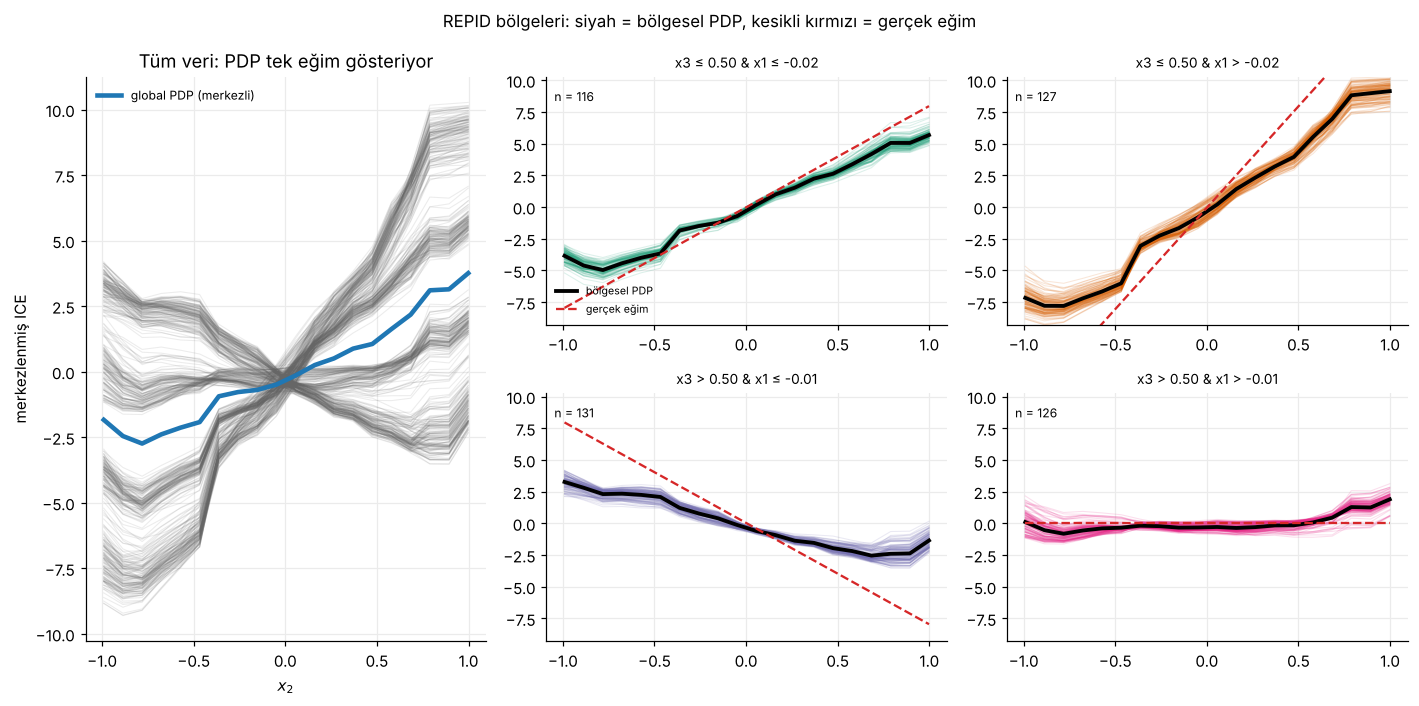

                 bölge   n  bölgesel PDP eğimi  gerçek eğim (ort.)
x3 ≤ 0.50 & x1 ≤ -0.02 116                5.72                8.00
x3 ≤ 0.50 & x1 > -0.02 127                9.54               16.00
x3 > 0.50 & x1 ≤ -0.01 131               -3.08               -8.00
x3 > 0.50 & x1 > -0.01 126                0.83                0.00
            global PDP 500                3.15                3.82


In [6]:
def gercek_egim(d):
    alt = sim.iloc[d["idx"]]
    egim = (-8 + 16 * (alt.x3 == 0) + 8 * (alt.x1 > sim.x1.mean())).mean()
    cizgi = egim * iz_sim
    return cizgi - cizgi.mean()                              # aynı merkezleme


fig = plt.figure(figsize=(13, 6.5))
ust = fig.add_subplot(2, 3, (1, 4))
ust.plot(iz_sim, Y_sim.T, color="0.4", alpha=0.12, lw=0.7)
ust.plot(iz_sim, Y_sim.mean(0), color="#1f77b4", lw=3, label="global PDP (merkezli)")
ust.set(xlabel="$x_2$", ylabel="merkezlenmiş ICE", title="Tüm veri: PDP tek eğim gösteriyor")
ust.legend(fontsize=8)
eks = [fig.add_subplot(2, 3, k) for k in (2, 3, 5, 6)]
bolgesel_ciz(eks, iz_sim, Y_sim, yap_sim, gercek=gercek_egim)
for ax in eks:
    ax.set_ylim(Y_sim.min(), Y_sim.max())
eks[0].legend(fontsize=7, loc="lower left")
fig.suptitle("REPID bölgeleri: siyah = bölgesel PDP, kesikli kırmızı = gerçek eğim", fontsize=11)
fig.tight_layout()
goster(fig, "01_simulasyon_repid.png")

egimler = pd.DataFrame([{"bölge": " & ".join(d["kural"]), "n": len(d["idx"]),
                         "bölgesel PDP eğimi": np.polyfit(iz_sim, ice_sim[d["idx"]].mean(0), 1)[0],
                         "gerçek eğim (ort.)": (-8 + 16 * (sim.iloc[d["idx"]].x3 == 0)
                                                + 8 * (sim.iloc[d["idx"]].x1 > sim.x1.mean())).mean()}
                        for d in yap_sim])
egimler.loc[len(egimler)] = ["global PDP", n, np.polyfit(iz_sim, ice_sim.mean(0), 1)[0],
                             (-8 + 16 * (sim.x3 == 0) + 8 * (sim.x1 > sim.x1.mean())).mean()]
print(egimler.round(2).to_string(index=False))

**Yorum.** REPID makaledeki gibi önce $x_3$'e, sonra iki tarafta da $x_1 \approx 0$'a bölüyor ve gürültü
özniteliklerine ($x_4, x_5, x_6$) hiç bölmüyor. Dört bölgesel PDP'nin eğimi gerçek eğimlere (−8, 0, +8, +16) yakın;
global PDP'nin eğimi ise hiçbir bölgeyi temsil etmiyor. Bölgesel eğimler gerçek değerlerden küçük çıkıyor: rastgele
orman tahminleri komşu gözlemlerin ortalaması olduğu için eğimleri ortalamaya doğru çeker. Sıralama ve işaretler
doğru; büyüklükler modelin sınırı (REPID modeli açıklar, gerçek fonksiyonu değil).

**Sağlamlık:** Bu tek bir veri çekilişi. Aşağıda 20 farklı tohumla aynı deneyi tekrarlıyorum.

In [7]:
sonuc = []
for tohum in range(20):
    r = np.random.default_rng(tohum)
    s = pd.DataFrame({"x1": r.uniform(-1, 1, n), "x2": r.uniform(-1, 1, n), "x3": r.choice([0, 1], n),
                      "x4": r.choice([0, 1], n, p=[0.7, 0.3]), "x5": r.choice([0, 1], n), "x6": r.normal(1, 5, n)})
    s["y"] = (0.2 * s.x1 - 8 * s.x2 + np.where(s.x3 == 0, 16 * s.x2, 0)
              + np.where(s.x1 > s.x1.mean(), 8 * s.x2, 0) + r.normal(0, 1, n))
    m = RandomForestRegressor(n_estimators=200, max_features=2, min_samples_leaf=5, random_state=tohum, n_jobs=-1)
    m.fit(s[SIM_OZ], s["y"])
    iz = np.linspace(s.x2.min(), s.x2.max(), 20)
    Y = merkezle(ice_hesapla(lambda D: m.predict(D[SIM_OZ]), s[SIM_OZ], "x2", iz))
    _, b, _ = repid(Y, s[["x1", "x3", "x4", "x5", "x6"]], derinlik=2, esik=0.0)
    sonuc.append({"ilk bölünme": b.iloc[0]["öznitelik"] if len(b) else "-",
                  "bölünen öznitelikler": "+".join(sorted(set(b["öznitelik"]))) if len(b) else "-",
                  "x1 eşiği (ort.)": b.loc[b["öznitelik"] == "x1", "eşik"].mean(),
                  "gürültüye bölünme": bool(set(b["öznitelik"]) & {"x4", "x5", "x6"})})
sonuc = pd.DataFrame(sonuc)
print(f"İlk bölünme x3: {(sonuc['ilk bölünme'] == 'x3').sum()}/20")
print(f"Bölünen öznitelikler tam olarak {{x1, x3}}: {(sonuc['bölünen öznitelikler'] == 'x1+x3').sum()}/20")
print(f"Gürültü özniteliğine bölünme: {sonuc['gürültüye bölünme'].sum()}/20")
print(f"x1 eşiğinin ortalaması: {sonuc['x1 eşiği (ort.)'].mean():.3f} (gerçek eşik ≈ 0)")

İlk bölünme x3: 20/20
Bölünen öznitelikler tam olarak {x1, x3}: 20/20
Gürültü özniteliğine bölünme: 0/20
x1 eşiğinin ortalaması: 0.010 (gerçek eşik ≈ 0)


## 3. Makalenin gerçek veri örneği: California Housing (makale Şekil 6; `california_housing.R`)

Yazarların ön işlemesi: hedef ve sayım değişkenleri log dönüşümlü, `ocean_proximity` sıralı tamsayı
(INLAND = 1, <1H OCEAN = 2, NEAR BAY = 3, NEAR OCEAN = 4, ISLAND = 5), eksik `total_bedrooms` medyanla dolduruluyor.
Model: tek gizli katmanlı sinir ağı (`nnet`, 20 nöron, ağırlık azaltma 0,1), **bütün veriyle** eğitiliyor.
Boylam (`longitude`) için 20 noktalı ICE; REPID ayarları: derinlik 3, `esik = 0,25`, `min_dugum = 30`.

Makalenin bulduğu bölgeler (şekil açıklamasından): **enlem > 34,5**; **enlem ≤ 34,5 ve iç bölge (INLAND)**;
**enlem ≤ 33,5 ve kıyı**; **33,5 < enlem ≤ 34,5 ve kıyı**.

**Farkım:** `nnet` yerine scikit-learn `MLPRegressor` (aynı mimari; girdiler standartlaştırıldı, L2 cezası 0,1).
Sinir ağının başlangıç ağırlıkları farklı olacağı için bölünme eşiklerinin birebir aynı çıkması beklenmez.

In [8]:
ev_ham = veri_oku()
ca = ev_ham.copy()
ca["ocean_proximity"] = ca["ocean_proximity"].map({"INLAND": 1, "<1H OCEAN": 2, "NEAR BAY": 3,
                                                   "NEAR OCEAN": 4, "ISLAND": 5})
ca["total_bedrooms"] = ca["total_bedrooms"].fillna(ca["total_bedrooms"].median())
ca["median_house_value"] = np.log10(ca["median_house_value"])
for s in ["median_income", "total_rooms", "total_bedrooms", "population", "households"]:
    ca[s] = np.log(ca[s])
CA_OZ = [c for c in ca.columns if c != "median_house_value"]

ag = Pipeline([("olcek", StandardScaler()),
               ("ag", MLPRegressor(hidden_layer_sizes=(20,), alpha=0.1, max_iter=1000, random_state=123))])
egit_ca, test_ca = train_test_split(ca, test_size=0.2, random_state=123)
ag.fit(egit_ca[CA_OZ], egit_ca["median_house_value"])
print(f"Sinir ağı, ayrılmış test kümesinde R² = {r2_score(test_ca['median_house_value'], ag.predict(test_ca[CA_OZ])):.3f}")
ag.fit(ca[CA_OZ], ca["median_house_value"])                  # yazarlar gibi bütün veriyle
f_ca = lambda D: ag.predict(D[CA_OZ])

iz_lon = np.linspace(ca.longitude.min(), ca.longitude.max(), 20)
ice_lon = ice_hesapla(f_ca, ca[CA_OZ], "longitude", iz_lon)
Y_lon = merkezle(ice_lon)
X_lon = ca[[c for c in CA_OZ if c != "longitude"]]
t0 = time.time()
yap_lon, bol_lon, kok_lon = repid(Y_lon, X_lon, derinlik=3, esik=0.25, min_dugum=30)
print(f"REPID {len(ca):,} ICE eğrisinde {time.time() - t0:.1f} sn sürdü.")
print(bol_lon.round(3).to_string(index=False))
print("\nEtkileşim ölçüsü:")
print(etkilesim_olcusu(bol_lon, X_lon.columns).round(3).to_string())

Sinir ağı, ayrılmış test kümesinde R² = 0.755


REPID 20,640 ICE eğrisinde 0.1 sn sürdü.
 derinlik          bölünen düğüm       öznitelik   eşik  kazanç     n
        1               tüm veri ocean_proximity  1.500   0.576 20640
        2 ocean_proximity ≤ 1.50        latitude 36.495   0.211  6551

Etkileşim ölçüsü:
ocean_proximity       0.576
latitude              0.211
housing_median_age    0.000
households            0.000
median_income         0.000
population            0.000
total_bedrooms        0.000
total_rooms           0.000


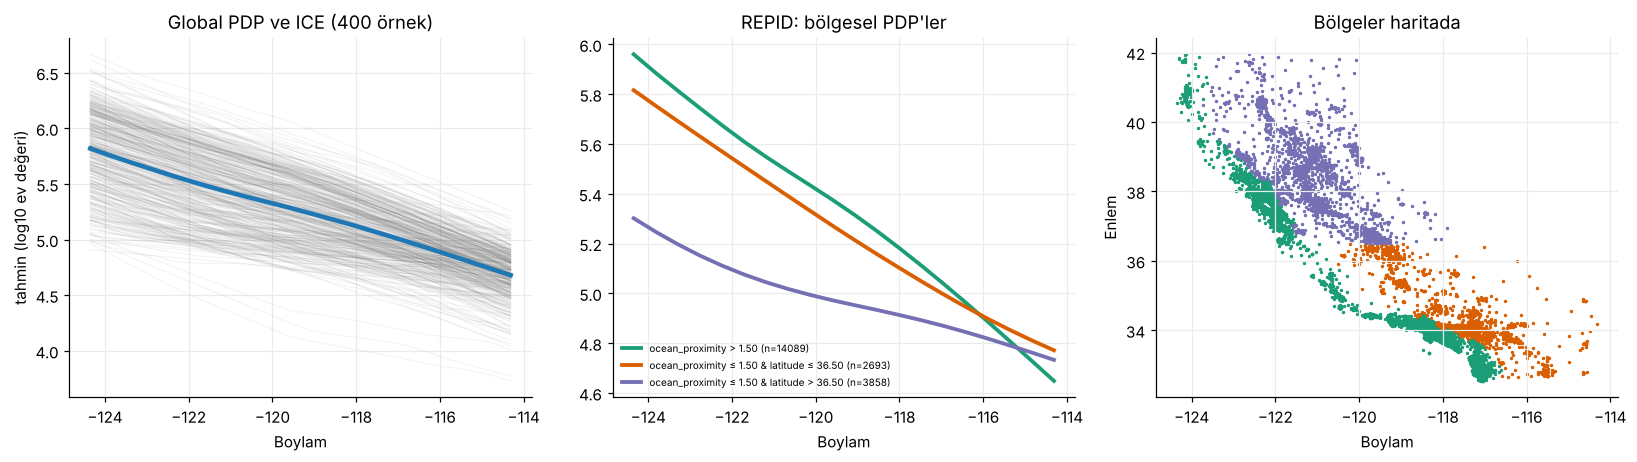

In [9]:
fig, (a, b, c) = plt.subplots(1, 3, figsize=(15, 4.3))
ornek = np.random.default_rng(0).choice(len(ca), 400, replace=False)
a.plot(iz_lon, ice_lon[ornek].T, color="0.4", alpha=0.08, lw=0.7)
a.plot(iz_lon, ice_lon.mean(0), color="#1f77b4", lw=3)
a.set(xlabel="Boylam", ylabel="tahmin (log10 ev değeri)", title="Global PDP ve ICE (400 örnek)")
for d, r in zip(yap_lon, BOLGE_RENK):
    b.plot(iz_lon, ice_lon[d["idx"]].mean(0), color=r, lw=2.5, label=f"{' & '.join(d['kural'])} (n={len(d['idx'])})")
b.set(xlabel="Boylam", title="REPID: bölgesel PDP'ler")
b.legend(fontsize=6.5, loc="lower left")
c.scatter(ca.longitude, ca.latitude, s=1, color="0.85")
for d, r in zip(yap_lon, BOLGE_RENK):
    c.scatter(ca.longitude.iloc[d["idx"]], ca.latitude.iloc[d["idx"]], s=1.5, color=r)
c.set(xlabel="Boylam", ylabel="Enlem", title="Bölgeler haritada")
fig.tight_layout()
goster(fig, "02_california_repid.png")

**Okuma notu:** `ocean_proximity ≤ 1,5` iç bölge (INLAND), `> 1,5` kıyı bölgeleri demek.

**Makaleyle karşılaştırma.** Makale de enlem ve okyanusa yakınlığa bölüyor; yani boylamın etkisinin **enlem ve
okyanusa yakınlıkla** etkileştiği bulgusu aynı. Bölünmelerin **sırası ve eşikleri** farklı: makalede önce enlem 34,5,
sonra iç bölge/kıyı ayrımı geliyor. Sinir ağı farklı başlangıçla farklı bir fonksiyon öğrenebildiği için bunu üç farklı
tohumla kontrol ediyorum.

In [10]:
tohum_sonuc = []
for tohum in [1, 2, 3]:
    ag_t = Pipeline([("olcek", StandardScaler()),
                     ("ag", MLPRegressor(hidden_layer_sizes=(20,), alpha=0.1, max_iter=1000, random_state=tohum))])
    ag_t.fit(ca[CA_OZ], ca["median_house_value"])
    Y_t = merkezle(ice_hesapla(lambda D: ag_t.predict(D[CA_OZ]), ca[CA_OZ], "longitude", iz_lon))
    _, b_t, _ = repid(Y_t, X_lon, derinlik=3, esik=0.25, min_dugum=30)
    tohum_sonuc.append({"tohum": tohum,
                        "bölünmeler (sırayla)": " → ".join(f"{r['öznitelik']} ({r['eşik']:.1f})" for _, r in b_t.iterrows()),
                        "açıklanan heterojenlik": round(b_t["kazanç"].sum(), 3)})
print(pd.DataFrame(tohum_sonuc).to_string(index=False))

 tohum  bölünmeler (sırayla)  açıklanan heterojenlik
     1 ocean_proximity (1.5)                   0.554
     2       latitude (35.3)                   0.453
     3 ocean_proximity (1.5)                   0.449


**Yorum.** Üç tohumda da bölünmeler **yalnızca enlem ve okyanusa yakınlık** üzerinden; başka hiçbir özniteliğe
bölünmüyor. Makalenin asıl bulgusu (boylamın etkisi bu iki öznitelikle etkileşiyor) yeniden üretiliyor. Ama ilk
bölünmenin hangisi olacağı sinir ağının başlangıcına bağlı. Bu da bir sınırlama: REPID modeli açıklar ve aynı mimarinin
farklı eğitimleri farklı açıklamalar verebilir.

## 4. Kendi verim: Bölüm 13 uygulamamdaki model ve gelir ICE'leri

Bölüm 13 uygulamamda aynı veride gradient boosting modeli kurmuş, test kümesinden 400 bölge için **medyan gelir**
ICE'lerini hesaplamış ve c-ICE eğrilerini k-ortalamalarla (k = 3) kümelemiştim. Bulgum: gelirin etkisi **bina yaşıyla**
etkileşiyor (Spearman ≈ 0,6); güçlü tepki kümesi çoğunlukla eski mahallelerden oluşuyordu.

Burada aynı model ve aynı ICE'lerle iki soruyu soruyorum:
1. REPID, önceden söylemeden **bina yaşına** bölüyor mu?
2. Aynı sayıda grupla k-ortalamalar ve REPID heterojenliğin ne kadarını açıklıyor? (k-ortalamalar kurala bağlı
   olmadığı için üst sınır gibi düşünülebilir; aradaki fark **yorumlanabilirliğin bedeli**.) Bu karşılaştırma benim
   ek deneyim; makalede yok. Yüzdeler tahmin doğruluğu değil, ICE eğrileri arasındaki şekil farklılığının açıklanan payı.

In [11]:
ev = ev_ham.copy()
ev["median_house_value"] = ev["median_house_value"] / 100_000
SAYISAL = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
           "population", "households", "median_income"]
OZ = SAYISAL + ["ocean_proximity"]
e_egitim, e_test = train_test_split(ev, train_size=2 / 3, random_state=42)          # uygulamamla aynı bölme
ev_model = Pipeline([
    ("on", ColumnTransformer([("kat", OneHotEncoder(handle_unknown="ignore"), ["ocean_proximity"])],
                             remainder="passthrough", sparse_threshold=0)),
    ("gb", HistGradientBoostingRegressor(max_iter=600, learning_rate=0.08, max_leaf_nodes=31, random_state=42)),
]).fit(e_egitim[OZ], e_egitim["median_house_value"])
print(f"Gradient boosting test R² = {r2_score(e_test['median_house_value'], ev_model.predict(e_test[OZ])):.3f}, "
      f"MAE = {mean_absolute_error(e_test['median_house_value'], ev_model.predict(e_test[OZ])) * 100_000:,.0f} $")

Xe = e_test[OZ].sample(400, random_state=1).reset_index(drop=True)                  # uygulamamdaki 400 bölge
iz_gelir = np.linspace(e_egitim.median_income.quantile(0.01), e_egitim.median_income.quantile(0.99), 50)
ice_gelir = ice_hesapla(ev_model.predict, Xe, "median_income", iz_gelir)
Y_gelir = merkezle(ice_gelir)
X_gelir = Xe.drop(columns="median_income").assign(
    ocean_proximity=Xe["ocean_proximity"].map({"INLAND": 1, "<1H OCEAN": 2, "NEAR BAY": 3, "NEAR OCEAN": 4, "ISLAND": 5}))

# Ayar: yazarların kodundaki varsayılan esik (0,1), derinlik 2, en küçük düğüm 30.
yap_g, bol_g, kok_g = repid(Y_gelir, X_gelir, derinlik=2, esik=0.1, min_dugum=30)
print(bol_g.round(3).to_string(index=False))
print("\nEtkileşim ölçüsü:")
print(etkilesim_olcusu(bol_g, X_gelir.columns).round(3).to_string())

Gradient boosting test R² = 0.838, MAE = 31,030 $
 derinlik              bölünen düğüm          öznitelik     eşik  kazanç   n
        1                   tüm veri housing_median_age   27.500   0.164 400
        2 housing_median_age ≤ 27.50        total_rooms 1312.000   0.044 191
        2 housing_median_age > 27.50          longitude -118.335   0.083 209

Etkileşim ölçüsü:
housing_median_age    0.164
longitude             0.083
total_rooms           0.044
households            0.000
latitude              0.000
ocean_proximity       0.000
population            0.000
total_bedrooms        0.000


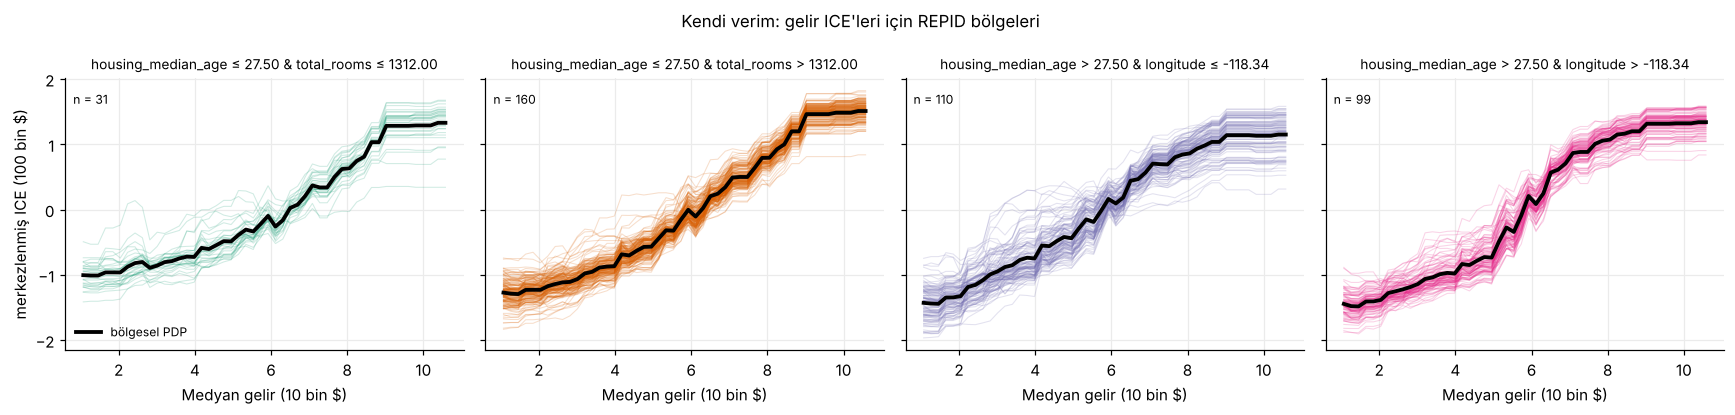

In [12]:
fig, eks = plt.subplots(1, len(yap_g), figsize=(4 * len(yap_g), 3.8), sharey=True)
eks = np.atleast_1d(eks)
bolgesel_ciz(eks, iz_gelir, Y_gelir, yap_g, alfa=0.2)
for ax in eks:
    ax.set_xlabel("Medyan gelir (10 bin $)")
eks[0].set_ylabel("merkezlenmiş ICE (100 bin $)")
eks[0].legend(fontsize=8)
fig.suptitle("Kendi verim: gelir ICE'leri için REPID bölgeleri", fontsize=11)
fig.tight_layout()
goster(fig, "03_kendi_veri_repid.png")

In [13]:
# REPID ile aynı sayıda grupla k-ortalamalar: heterojenliğin açıklanan payı
k = len(yap_g)
km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(Y_gelir)
het_km = sum(heterojenlik(Y_gelir[km.labels_ == c]) for c in range(k))
het_repid = sum(heterojenlik(Y_gelir[d["idx"]]) for d in yap_g)
karsilastirma = pd.DataFrame({
    "grup sayısı": [1, k, k],
    "açıklanan heterojenlik (%)": [0, 100 * (1 - het_repid / kok_g), 100 * (1 - het_km / kok_g)],
    "grupları tanımlayan kural": ["–", "var (ağaç)", "yok"],
}, index=["Global PDP", "REPID", "k-ortalamalar"]).round(1)
print(karsilastirma.to_string())

etiket_repid = np.empty(len(Xe), dtype=object)
for d in yap_g:
    etiket_repid[d["idx"]] = " & ".join(d["kural"])
yas_grubu = pd.cut(Xe["housing_median_age"], [0, 20, 35, 52],
                   labels=["Yeni (≤20)", "Orta (21–35)", "Eski (>35)"]).astype(str)
print("\nREPID bölgelerinin bina yaşı gruplarına dağılımı (satır yüzdesi):")
print(pd.crosstab(etiket_repid, yas_grubu, normalize="index").round(2).to_string())
print("\nREPID bölgeleri ile k-ortalamalar kümeleri (gözlem sayısı):")
print(pd.crosstab(etiket_repid, km.labels_).to_string())

               grup sayısı  açıklanan heterojenlik (%) grupları tanımlayan kural
Global PDP               1                         0.0                         –
REPID                    4                        29.1                var (ağaç)
k-ortalamalar            4                        57.9                       yok

REPID bölgelerinin bina yaşı gruplarına dağılımı (satır yüzdesi):
housing_median_age                                  Eski (>35)  Orta (21–35)  Yeni (≤20)
row_0                                                                                   
housing_median_age > 27.50 & longitude > -118.34          0.61          0.39        0.00
housing_median_age > 27.50 & longitude ≤ -118.34          0.57          0.43        0.00
housing_median_age ≤ 27.50 & total_rooms > 1312.00        0.00          0.39        0.61
housing_median_age ≤ 27.50 & total_rooms ≤ 1312.00        0.00          0.29        0.71

REPID bölgeleri ile k-ortalamalar kümeleri (gözlem sayısı):
col_0         

**Yorum.**

* REPID'in **ilk bölünmesi bina yaşı (≤ 27,5 yıl)**. Bölüm 13 uygulamamda bu etkileşimi c-ICE'leri renklendirip
  k-ortalamalarla kümeleyerek ve sonradan bina yaşıyla karşılaştırarak bulmuştum. REPID ise kimse söylemeden ve bir
  kural olarak buluyor.
* İkinci seviyede eski mahalleler boylama (Los Angeles'ın doğusu/batısı), yeni mahalleler toplam oda sayısına göre
  ayrılıyor; bu kazançlar küçük (%4–8).
* **Yorumlanabilirliğin bedeli:** Aynı sayıda (4) grupla k-ortalamalar heterojenliğin çok daha büyük bir kısmını
  açıklıyor, çünkü grupları istediği gibi seçebiliyor. REPID'in grupları ise "bina yaşı ≤ 27,5" gibi kurallara bağlı.
  k-ortalamalar daha homojen gruplar verir ama gruplar bir kurala karşılık gelmez; REPID daha az homojen ama her grup
  bir cümleyle tanımlanabilir.

**Sağlamlık:** 400 bölge küçük bir örneklem. İlk bölünmenin örnekleme bağlı olup olmadığını beş farklı 400'lük
örneklem ve 2.000 bölgelik bir örneklemle kontrol ediyorum.

In [14]:
ilk = []
for boyut, tohum in [(400, 1), (400, 2), (400, 3), (400, 4), (400, 5), (2000, 1)]:
    Xs = e_test[OZ].sample(boyut, random_state=tohum).reset_index(drop=True)
    Ys = merkezle(ice_hesapla(ev_model.predict, Xs, "median_income", iz_gelir))
    Xb = Xs.drop(columns="median_income").assign(
        ocean_proximity=Xs["ocean_proximity"].map({"INLAND": 1, "<1H OCEAN": 2, "NEAR BAY": 3, "NEAR OCEAN": 4, "ISLAND": 5}))
    _, b_s, _ = repid(Ys, Xb, derinlik=1, esik=0.1, min_dugum=30)
    ilk.append({"örneklem": f"{boyut} bölge, tohum {tohum}",
                "ilk bölünme": f"{b_s.iloc[0]['öznitelik']} ≤ {b_s.iloc[0]['eşik']:.1f}" if len(b_s) else "bölünme yok",
                "kazanç": round(b_s.iloc[0]["kazanç"], 3) if len(b_s) else 0})
print(pd.DataFrame(ilk).to_string(index=False))

           örneklem               ilk bölünme  kazanç
 400 bölge, tohum 1 housing_median_age ≤ 27.5   0.164
 400 bölge, tohum 2 housing_median_age ≤ 27.5   0.159
 400 bölge, tohum 3 housing_median_age ≤ 26.5   0.161
 400 bölge, tohum 4 housing_median_age ≤ 27.5   0.170
 400 bölge, tohum 5 housing_median_age ≤ 27.5   0.166
2000 bölge, tohum 1 housing_median_age ≤ 27.5   0.164


İncelenen altı örneklemde ilk bölünme bina yaşı oldu (eşik 26,5–27,5 yıl, kazanç %16–17); bu deneyde sonuç örneklem
değişimine karşı tutarlı göründü.

## 5. Sınırlamalar (savunma için)

1. **Açgözlü (greedy) ağaç.** Her adımda en iyi tek bölünme seçilir; birlikte daha iyi olacak bölünme çiftleri
   kaçırılabilir. Bölünmeler eksenlere paraleldir.
2. **Korelasyonlu öznitelikler.** İki öznitelik birbirine çok bağlıysa ağaç ikisinden birini seçer; hangisinin
   "gerçek" etkileşim ortağı olduğunu ayıramaz. (Makale bu durumu Bölüm 4.1'de ayrıca inceliyor; bu defterde
   yeniden üretilmedi.)
3. **Durma kuralı ve `esik`.** Kaç bölge çıkacağı `esik`, `derinlik` ve `min_dugum` seçimlerine bağlı. Makalenin
   California örneğinde `esik = 0,25`, simülasyonunda iki derinlik kullanıldı.
4. **Merkezleme seçimi.** REPID eğrileri ortalamada merkezliyor; seviye farkları (ör. kıyı bölgelerinin daha pahalı
   olması) bölünmeyi etkilemez. Bu bilinçli bir seçim: amaç **etkileşimi**, yani şekil farkını bulmak.
5. **ICE'nin kendi sınırları devam eder.** ICE eğrileri öznitelikler korelasyonluyken veri dışı noktalar içerebilir
   (Bölüm 12 makale çalışmamın konusu). REPID bu noktaları da ortalamaya katar.
6. **Model açıklaması, gerçek dünya değil.** Bulunan etkileşimler modelin etkileşimleridir; nedensel yorumlanamaz.